MD# 03 · PD vs control cell-type composition

Runs `analysis/04_composition_test.py`: per region, empirical logit of each donor's proportion, `y ~ PD + C(dataset)` (OLS), BH-FDR within region.
Neuron-sorted / enriched libraries are excluded (metadata `enriched = TRUE`, plus midbrain libraries with > 40 % neurons, see `results/composition_test/neuron_enriched_libraries.csv`).

In [1]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
# Notebooks run from the project root so that results/ and config/ resolve.
if os.path.basename(os.getcwd()) == "notebooks": os.chdir("..")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
import sys; sys.path.insert(0, "analysis")
import importlib; comp = importlib.import_module("04_composition_test")
res = comp.run()
res.round(4)

,region,cell_type,donors_PD,donors_Ctrl,pct_PD,pct_Ctrl,logit_diff_PD_vs_Ctrl,p,datasets_lower_in_PD,datasets_higher_in_PD,padj
4,Cortex,Micro_PVM,21,21,7.89,4.83,0.623,0.0216,0,3,0.1724
0,Cortex,Astro,21,21,10.12,11.37,-0.147,0.5166,2,1,0.9525
1,Cortex,EN,21,21,32.75,35.09,-0.076,0.6011,2,1,0.9525
2,Cortex,Endo,21,21,0.43,0.62,-0.056,0.8316,2,1,0.9525
5,Cortex,Mural,21,21,0.17,0.19,-0.027,0.8607,2,1,0.9525
6,Cortex,OPC,21,21,8.03,8.35,-0.019,0.9126,2,1,0.9525
3,Cortex,IN,21,21,16.82,16.86,0.009,0.9454,1,2,0.9525
7,Cortex,Oligo,21,21,22.83,21.91,0.014,0.9525,2,1,0.9525
11,Midbrain,DA_Neu,51,59,0.90,2.27,-0.581,0.0040,6,1,0.0484
10,Midbrain,CADPS2_Neu,51,59,0.12,0.56,-0.209,0.1131,4,1,0.4932


In [3]:
res[res.padj < 0.25].round(4)

,region,cell_type,donors_PD,donors_Ctrl,pct_PD,pct_Ctrl,logit_diff_PD_vs_Ctrl,p,datasets_lower_in_PD,datasets_higher_in_PD,padj
4,Cortex,Micro_PVM,21,21,7.89,4.83,0.623,0.0216,0,3,0.1724
11,Midbrain,DA_Neu,51,59,0.90,2.27,-0.581,0.0040,6,1,0.0484


MD## Midbrain DA neurons, per donor

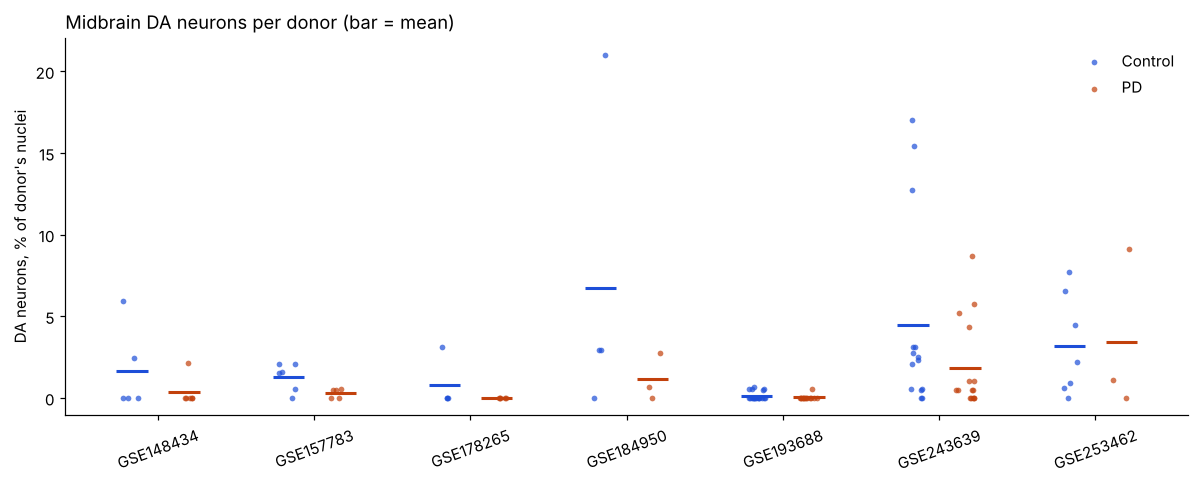

In [4]:
d = pd.read_csv("results/composition_test/donor_celltype_proportions.csv")
m = d[(d.region_group == "Midbrain") & d.diagnosis.isin(["PD", "Control"])]
ds = sorted(m.dataset.unique())
fig, ax = plt.subplots(figsize=(11, 4.5)); rng = np.random.default_rng(0)
for i, dsn in enumerate(ds):
    for j, (dx, col) in enumerate([("Control", "#1D4ED8"), ("PD", "#C2410C")]):
        v = 100*m[(m.dataset == dsn) & (m.diagnosis == dx)].DA_Neu
        x = i*3 + j + rng.uniform(-.18, .18, len(v))
        ax.scatter(x, v, s=14, c=col, alpha=.7, lw=0, label=dx if i == 0 else None)
        if len(v): ax.hlines(v.mean(), i*3+j-.3, i*3+j+.3, color=col, lw=2)
ax.set_xticks([i*3+.5 for i in range(len(ds))]); ax.set_xticklabels(ds, rotation=20)
ax.set_ylabel("DA neurons, % of donor's nuclei"); ax.legend(frameon=False)
ax.set_title("Midbrain DA neurons per donor (bar = mean)", loc="left"); plt.tight_layout(); plt.show()

MD**Note.** The lab-meeting slide (18 Nov) reported DA_Neu p = 0.0037, FDR 0.034 from an earlier in-session version of this test that tested fewer cell types. This script tests every cell type present in ≥ 10 donors, so the BH correction covers more tests: p = 0.004, FDR ≈ 0.05. The direction (lower in PD in 6 of 7 datasets) is unchanged.